# GDS export: placing layouts and periodic arrays on one chip

`metashapes.gds` turns `Layout`s and `UnitCell` arrays into a GDS file (needs `gdstk`). This notebook

1. builds two aperiodic lenses and a batch of periodic unit cells,
2. places them on a `GDSAssembly` (layouts by position, arrays by position + number of periods),
3. checks the placement (overlaps, spacing) and plots the footprints,
4. writes the file and looks at its cell hierarchy.

The model here is drawn in **nm** (`coord_unit=1e-9`); the file is written in µm with a 1 nm grid, the usual GDS convention.

In [1]:
import math
import matplotlib.pyplot as plt
import shapely.plotting
import gdstk

from metashapes import Lattice
from metashapes.shape import Ellipse
from metashapes.generators import GeneratorConfig
from metashapes.generators.random import RandomUnitCellGenerator
from metashapes.layout import (LayoutConfig, LayoutGenerator, LatticeSites, ParametricSource,
                               RandomSites, SamplerSource)
from metashapes.gds import GDSAssembly

## 1. Items to place

In [2]:
# two aperiodic lenses (10 µm apertures)
domain = Ellipse(center=(0, 0), axes=(10_000, 10_000))
random_lens = LayoutGenerator(
    LayoutConfig(seed=1, min_gap=60, edge_margin=150, max_consecutive_failures=300),
    sites=RandomSites(),
    source=SamplerSource(GeneratorConfig(allowed_shapes=("Ellipse", "Rectangle", "Star"),
                                         min_feature_size=40, min_shape_size=80),
                         atom_box=(300, 300)),
).generate_one(domain)

radius = lambda x, y: 40 + 80 * math.hypot(x, y) / 5_000      # discs grow toward the edge
field_lens = LayoutGenerator(
    LayoutConfig(edge_margin=150),
    sites=LatticeSites(Lattice.hexagonal(350)),
    source=ParametricSource(Ellipse, {"axes": lambda x, y: (2 * radius(x, y),) * 2}),
).generate_one(domain)

# a batch of periodic unit cells (400 nm square lattice)
cells = RandomUnitCellGenerator(GeneratorConfig(
    seed=3, target_count=6, allowed_shapes=("Ellipse", "Cross", "Rectangle"),
    min_feature_size=40, max_num_shapes=1,
)).generate(Lattice.rectangular(400, 400))
print(len(random_lens), "atoms,", len(field_lens), "atoms,", len(cells.unit_cells), "unit cells")

915 atoms, 661 atoms, 6 unit cells


## 2. Placement

- `place(layout, at=(x, y))`: the layout's own (0, 0) goes to `at`.
- `place_array(cell, at, repeats=(n1, n2))`: an `n1 × n2` array, centred on `at` by default (`anchor="origin"` puts lattice point (0, 0) there). Arrays are made of whole atoms, so the outer edge is ragged; nothing is clipped.
- `place_grid(batch, origin, pitch, cols, repeats=...)`: a batch on a grid, each item centred in its slot.
- `text=` attaches an optional description, written as a label on a separate text layer.

In [3]:
chip = GDSAssembly(coord_unit=1e-9, tolerance=1.0)            # 1 nm max chord error
chip.place(random_lens, at=(0, 0), name="random_lens", text="random lens")
chip.place(field_lens, at=(12_000, 0), name="field_lens", text="field lens")
chip.place_grid(cells, origin=(-1_000, -12_000), pitch=(10_000, 10_000), cols=3,
                repeats=(20, 20), name_prefix="cell")
for p in chip.placements:
    print(f"{p.name:<12} {p.kind:<6} offset=({p.offset[0]:9.1f}, {p.offset[1]:9.1f})  repeats={p.repeats}")

random_lens  layout offset=(      0.0,       0.0)  repeats=None
field_lens   layout offset=(  12000.0,       0.0)  repeats=None
cell_0       array  offset=(  -5000.0,  -16000.0)  repeats=(20, 20)
cell_1       array  offset=(   5000.0,  -16000.0)  repeats=(20, 20)
cell_2       array  offset=(  15000.0,  -16000.0)  repeats=(20, 20)
cell_3       array  offset=(  -5000.0,  -26000.0)  repeats=(20, 20)
cell_4       array  offset=(   5000.0,  -26000.0)  repeats=(20, 20)
cell_5       array  offset=(  15000.0,  -26000.0)  repeats=(20, 20)


## 3. Checks and footprints

check (min spacing 1 µm): OK


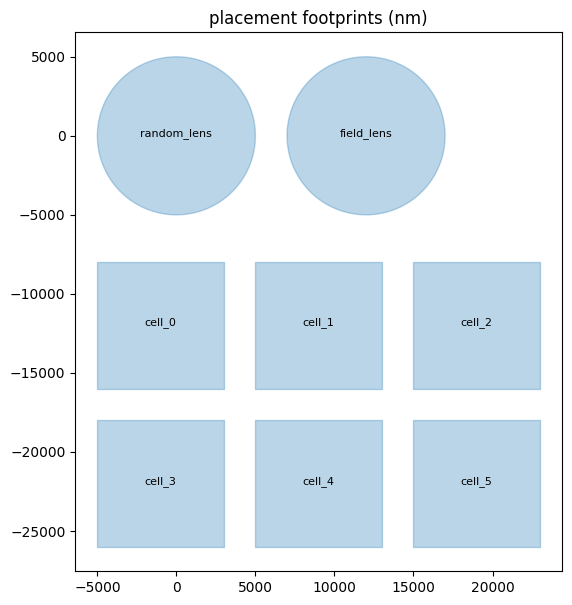

In [4]:
print("check (min spacing 1 µm):", chip.check(min_spacing=1_000) or "OK")

fig, ax = plt.subplots(figsize=(7, 7))
for name, fp in chip.footprints().items():
    shapely.plotting.plot_polygon(fp, ax=ax, add_points=False, alpha=0.3)
    ax.annotate(name, fp.centroid.coords[0], ha="center", fontsize=8)
ax.set_aspect("equal"); ax.set_title("placement footprints (nm)");

A deliberately colliding placement is reported, and `write_gds` refuses to write it unless `allow_overlap=True`:

In [5]:
bad = GDSAssembly(coord_unit=1e-9)
bad.place(random_lens, at=(0, 0), name="a")
bad.place(field_lens, at=(8_000, 0), name="b")
print(bad.check())

["overlap: 'a' and 'b' footprints overlap (area 8.167e+06)"]


## 4. Write and inspect

In [6]:
lib = chip.write_gds("chip.gds", min_spacing=1_000)
top = lib.top_level()[0]
cells = {c.name: c for c in lib.cells}
subcells = [n for n in cells if "__A" in n]
print(f"{len(lib.cells)} cells, top cell has {len(top.references)} references")
print(f"random_lens: {len(cells['random_lens'].polygons)} plain polygons (every atom differs)")
print(f"field_lens : {len(cells['field_lens'].references)} references to {len(subcells)} shared atom cells, "
      f"{len(cells['field_lens'].polygons)} plain polygon(s)")
print(f"cell_0     : {len(cells['cell_0'].polygons)} polygon(s), placed by "
      f"{sum(r.cell.name == 'cell_0' for r in top.references)} array reference(s) of "
      f"{max(r.repetition.size for r in top.references if r.cell.name == 'cell_0')} copies")
(x0, y0), (x1, y1) = top.bounding_box()
print(f"chip extent: {x1 - x0:.1f} x {y1 - y0:.1f} µm")

65 cells, top cell has 8 references
random_lens: 915 plain polygons (every atom differs)
field_lens : 660 references to 56 shared atom cells, 1 plain polygon(s)
cell_0     : 1 polygon(s), placed by 1 array reference(s) of 400 copies
chip extent: 28.0 x 30.8 µm


How the hierarchy came out:

- **random lens:** every atom is different, so all are plain polygons.
- **field lens:** discs at the same distance from the centre have the same radius, so equal atoms share one sub-cell and are placed by references. An atom used only once stays a plain polygon.
- **arrays:** each is one cell with one period, placed by a single GDS array reference.

A zoom into the written file (flattened) at the field lens edge and inside one array:

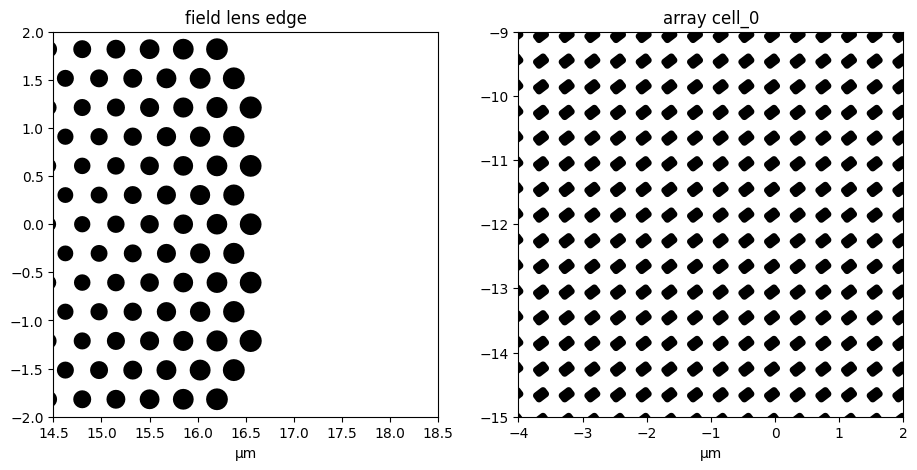

In [7]:
flat = top.copy("flat"); flat.flatten()
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (cx, cy, w) in zip(axes, [(16.5, 0.0, 2.0), (chip.footprint(chip.placements[2]).centroid.x / 1e3,
                                                   chip.footprint(chip.placements[2]).centroid.y / 1e3, 3.0)]):
    for p in flat.polygons:
        (px0, py0), (px1, py1) = p.bounding_box()
        if px1 < cx - w or px0 > cx + w or py1 < cy - w or py0 > cy + w:
            continue
        ax.fill(*p.points.T, color="k", lw=0)
    ax.set_xlim(cx - w, cx + w); ax.set_ylim(cy - w, cy + w); ax.set_aspect("equal")
    ax.set_xlabel("µm")
axes[0].set_title("field lens edge"); axes[1].set_title("array cell_0");

For one object, `save_gds(path, layout)` or `save_gds(path, unit_cell, repeats=(n1, n2))` does the same in one call. Layouts with 10⁵ all-different atoms take ~50 s to convert; pass `workers=8` to `GDSAssembly` to use several processes.